# From AERONET-OC to top of atmosphere

This tutorial runs the whole RadCalNet-OC chain on one day of measurements of the AERONET-OC station
*Acqua Alta Oceanographic Tower* (AAOT, northern Adriatic Sea, 45.31° N, 12.51° E), on 2 July 2025:

1. the input time series prepared from the AERONET-OC Level 2.0 data (gases, aerosols, $R_{rs}$);
2. the retrieval of the aerosol model mixture from the spectral aerosol optical thickness;
3. the simulation of the top-of-atmosphere (TOA) reflectance at full spectral resolution for several
   viewing angles;
4. the convolution to 10 nm bands, the format of the RadCalNet-OC products;
5. the propagation of the uncertainty of the water-leaving signal and of the aerosol optical thickness
   to the TOA reflectance.

The input file is small (10 measurements) and is shipped with this documentation
(`docs/source/notebook/data`): the tutorial runs as is, with the full TOA look-up table (see
{doc}`../installation`) or, with a lower accuracy, with the light one of the package.

In [1]:
import logging

import matplotlib as mpl
import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import xarray as xr

import radcalnet_oc as radoc
# radcalnet_oc sets the root logger to INFO: show only the warnings in this tutorial
logging.getLogger().setLevel(logging.WARNING)

print(f'radcalnet_oc {radoc.__version__}')

radcalnet_oc 1.0.1


## Input time series

The input file gathers, for each AERONET-OC measurement (dimension `time`):

- the atmospheric parameters of the AERONET-OC file, converted to the units of the processor: total
  columns of water vapour `tcwv`, ozone `tco3` and nitrogen dioxide `tcno2` (kg m$^{-2}$), surface
  pressure (hPa), solar zenith angle `sza`, aerosol optical thickness at 550 and 865 nm and Ångström
  exponent;
- the normalized aerosol optical thickness `naot`, $\tau_a(\lambda)/\tau_a(550)$, at the AERONET-OC
  bands (dimension `wl_aeronet`);
- the remote-sensing reflectance at the AERONET-OC bands, `Rrs_Lwn` (from $L_{wn}$), and its
  hyperspectral reconstruction from 350 to 1100 nm, `Rrs` (dimension `wl`), computed with the
  *InvRrs* bio-optical inversion (see {doc}`../processing_chain`).

In [2]:
input_db = xr.open_dataset('data/radcalnet_oc_input_AAOT_OCv3.lev20.nc').load()
input_db

<xarray.Dataset> Size: 38kB
Dimensions:      (time: 10, wl_aeronet: 11, wl: 200)
Coordinates:
  * time         (time) datetime64[ns] 80B 2025-07-02T09:48:10 ... 2025-07-02...
  * wl_aeronet   (wl_aeronet) float64 88B 400.0 412.0 443.0 ... 865.0 1.02e+03
  * wl           (wl) float64 2kB 350.0 353.8 357.5 ... 1.096e+03 1.1e+03
Data variables: (12/15)
    tcwv         (time) float64 80B 34.32 34.75 34.73 ... 33.65 33.53 33.36
    tco3         (time) float64 80B 0.007223 0.007222 ... 0.007221 0.007221
    tcno2        (time) float64 80B 5.416e-06 5.416e-06 ... 5.414e-06 5.414e-06
    pressure     (time) float64 80B 1.016e+03 1.016e+03 ... 1.015e+03 1.015e+03
    sza          (time) float64 80B 28.17 24.07 23.72 ... 29.53 30.17 30.82
    day_of_year  (time) int64 80B 183 183 183 183 183 183 183 183 183 183
    ...           ...
    naot         (time, wl_aeronet) float64 880B 1.812 1.729 ... 0.4419 0.3323
    Rrs_Lwn      (time, wl_aeronet) float64 880B 0.003577 0.003441 ... 4.702e-06
    Rrs_Lwn_IOP  (time, wl_aeronet) float64 880B 0.003359 0.003225 ... 4.702e-06
    Rrs_Lwn_fQ   (time, wl_aeronet) float64 880B 0.003382 0.003239 ... 4.702e-06
    Rrs          (time, wl) float64 16kB 0.001237 0.001305 0.001377 ... 0.0 0.0
    Rrs_nadir    (time, wl) float64 16kB 0.001196 0.001262 0.00133 ... 0.0 0.0

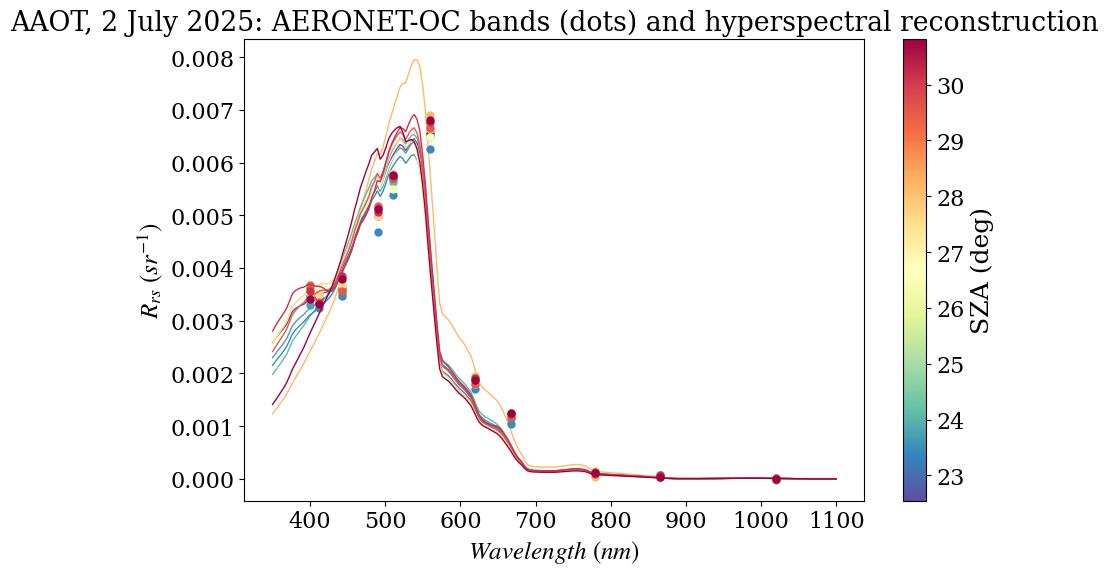

In [3]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=input_db.sza.min(), vmax=input_db.sza.max())
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig, ax = plt.subplots(figsize=(10, 6))
for it in range(input_db.sizes['time']):
    data = input_db.isel(time=it)
    color = cmap(norm(data.sza))
    data.Rrs.plot(ax=ax, color=color, lw=1)
    data.Rrs_Lwn.plot(ax=ax, color=color, marker='o', ls='', ms=5)
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')
ax.set_title('AAOT, 2 July 2025: AERONET-OC bands (dots) and hyperspectral reconstruction')
fig.colorbar(sm, ax=ax, label='SZA (deg)')
plt.show()

The hyperspectral $R_{rs}$ is the fit of a bio-optical model to the AERONET-OC bands: it follows their
spectral shape and magnitude but not each band value exactly (differences up to about 10 % here).
This reconstruction is a source of uncertainty of the simulation, not assessed below.

## Aerosol model mixture

The proportions of the OPAC aerosol models are retrieved, for each measurement, from the spectral shape
of the aerosol optical thickness measured by the sun photometer: the normalized AOT is fitted with a
mixture of the desert, maritime clean and water-soluble models (see {ref}`methods-aerosol`). The
measurements without aerosol data are discarded: the simulation needs both $R_{rs}$ and the aerosols.

In [4]:
naot = input_db.naot.dropna('wl_aeronet', how='all').dropna('time', how='all')
input_db = input_db.sel(time=naot.time)

vza = xr.DataArray([0., 20., 40.], coords={'vza': [0., 20., 40.]}, dims='vza')
process = radoc.Process(input_db, vza=vza, azi=[90.])
print(f'TOA LUT: {process.lut.lut_file}')

aerosol = radoc.Aerosol(naot, process.lut.naot_lut)
aerosol.process()
aerosol_combination = aerosol.model_db.aerosol_combination
aerosol_combination.to_pandas().round(2)

TOA LUT: /data/grs/grsdata/toa_lut_opac_wind_v3.nc


model,ARCT_rh70,COAV_rh70,DESE_rh70,MACL_rh70,URBA_rh70,WASO_rh0
time,,,,,,
2025-07-02 09:48:10,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 10:28:28,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 10:33:15,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 11:28:34,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 11:48:01,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 12:23:41,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 12:33:15,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 12:47:57,0.0,0.0,0.0,0.0,0.0,1.0
2025-07-02 12:52:43,0.0,0.0,0.0,0.0,0.0,1.0


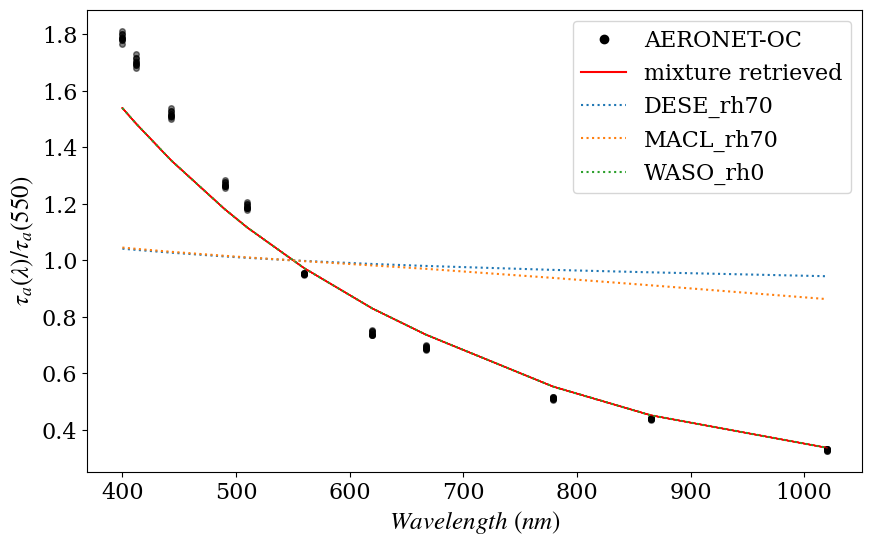

In [5]:
# normalized AOT of the mixture retrieved, compared to the measured one
naot_fit = (aerosol_combination * aerosol.naot_lut_all).sum('model')

fig, ax = plt.subplots(figsize=(10, 6))
for it in range(naot.sizes['time']):
    ax.plot(naot.wl_aeronet, naot.isel(time=it), 'ko', ms=4, alpha=0.5)
    ax.plot(naot_fit.wl, naot_fit.isel(time=it), 'r-', lw=1, alpha=0.5)
ax.plot([], [], 'ko', label='AERONET-OC')
ax.plot([], [], 'r-', label='mixture retrieved')
for model in ['DESE_rh70', 'MACL_rh70', 'WASO_rh0']:
    aerosol.naot_lut_all.sel(model=model).plot(ax=ax, ls=':', lw=1.5, label=model)
ax.legend()
ax.set_title('')
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel(r'$\tau_a(\lambda)/\tau_a(550)$')
plt.show()

On this day, the AOT decreases with the wavelength more steeply than for any of the three models
(Ångström exponent of 1.8, small particles): the fit gives the water-soluble model alone, the
steepest one, at all times. The mixture retrieved underestimates the AOT in the blue, which is one
of the limits of a mixture of a few predefined models.

## Simulation at the top of atmosphere

The simulation is run with the mixture retrieved for each measurement, for three viewing zenith angles
and a relative azimuth of 90°. The outputs, at the full spectral resolution of the gaseous absorption
tables (about 0.1 nm), are stored in `process.radcalnet_db`: TOA reflectance `Rtoa`, atmospheric
reflectance `Ratm`, irradiance at the bottom (`Ed`) and top (`E0`) of the atmosphere.

In [6]:
process.execute(aerosol_combination=aerosol_combination)
radcalnet_db = process.radcalnet_db
radcalnet_db

<xarray.Dataset> Size: 16MB
Dimensions:              (time: 10, wl: 21532, vza: 3, model: 6)
Coordinates:
  * time                 (time) datetime64[ns] 80B 2025-07-02T09:48:10 ... 20...
    aot_ref              (time) float64 80B 0.1513 0.151 0.1508 ... 0.138 0.1368
    sza                  (time) float64 80B 28.17 24.07 23.72 ... 30.17 30.82
  * wl                   (wl) float64 172kB 350.1 350.3 ... 2.499e+03 2.5e+03
  * vza                  (vza) float64 24B 0.0 20.0 40.0
  * model                (model) <U9 216B 'ARCT_rh70' 'COAV_rh70' ... 'WASO_rh0'
Data variables: (12/14)
    Ed                   (time, wl) float64 2MB 710.6 672.4 ... 0.00208 0.4296
    Ratm                 (time, wl, vza) float64 5MB 0.2565 0.2589 ... 3.874e-08
    Rrs                  (time, wl) float64 2MB 0.001239 0.001243 ... 0.0 0.0
    E0                   (time, wl) float64 2MB 1.002e+03 947.3 ... 42.43 42.43
    Rtoa                 (time, wl, vza) float64 5MB 0.2585 0.2609 ... 3.874e-08
    tcwv                 (time) float64 80B 34.32 34.75 34.73 ... 33.53 33.36
    ...                   ...
    pressure             (time) float64 80B 1.016e+03 1.016e+03 ... 1.015e+03
    aot550               (time) float64 80B 0.1513 0.151 0.1508 ... 0.138 0.1368
    aot865               (time) float64 80B 0.06665 0.06682 ... 0.06076 0.06047
    ang_exp              (time) float64 80B 1.81 1.8 1.8 ... 1.815 1.811 1.804
    aerosol_combination  (time, model) float64 480B 0.0 0.0 ... 0.0 1.0
    D2                   (time) float64 80B 0.9666 0.9666 ... 0.9666 0.9666

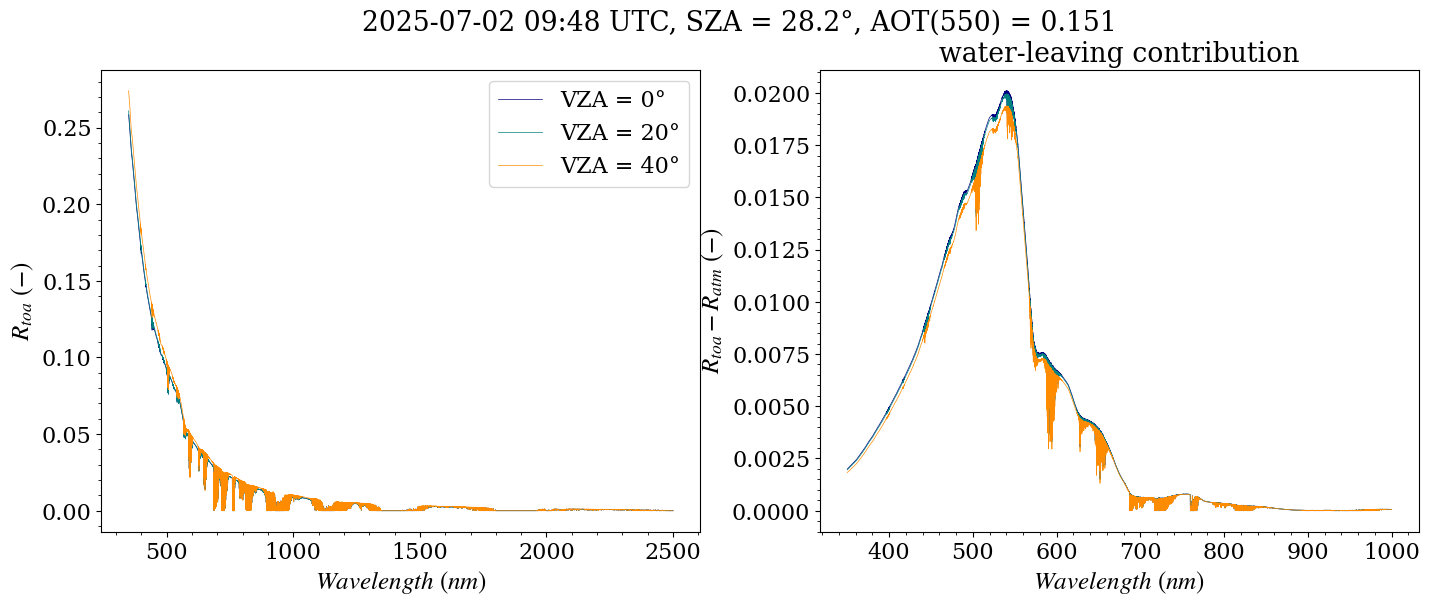

In [7]:
data = radcalnet_db.isel(time=0)
colors = {0.: 'navy', 20.: 'teal', 40.: 'darkorange'}

fig, axs = plt.subplots(1, 2, figsize=(17, 6))
for vza_, color in colors.items():
    rtoa, ratm = data.Rtoa.sel(vza=vza_), data.Ratm.sel(vza=vza_)
    rtoa.plot(ax=axs[0], color=color, lw=0.5, label=f'VZA = {vza_:.0f}°')
    (rtoa - ratm).sel(wl=slice(350, 1000)).plot(ax=axs[1], color=color, lw=0.5)
axs[0].set_ylabel(r'$R_{toa}\ (-)$')
axs[0].legend()
axs[0].set_title('')
axs[1].set_ylabel(r'$R_{toa} - R_{atm}\ (-)$')
axs[1].set_title('water-leaving contribution')
for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
fig.suptitle(f"{data.time.dt.strftime('%Y-%m-%d %H:%M').values} UTC, SZA = {float(data.sza):.1f}°, "
             f"AOT(550) = {float(data.aot550):.3f}")
plt.show()

The water-leaving contribution peaks in the green, at about a quarter of the TOA reflectance at
550 nm, against 5 % in the blue where the Rayleigh scattering dominates; it vanishes in the near
infrared. The gaseous absorption bands (O$_3$ in the visible, O$_2$ at 760 nm, water vapour at 940 and
1140 nm) are resolved at full resolution, and are deeper for the longer path at VZA = 40°.

## Convolution to 10 nm bands

The RadCalNet-OC products give the TOA reflectance every 10 nm, with a 10 nm full width at half maximum
(FWHM). The full resolution outputs are convolved with super-Gaussian spectral responses (exponent 3,
see {ref}`spectral_convolution`); the remote-sensing reflectance, smooth, is interpolated. For a given
sensor, the same is done with its own band centres and widths.

In [8]:
central_wl = np.arange(350, 2500, 10)
spectral = radoc.Spectral(central_wl, fwhm=10)

bands = []
for name, values in radcalnet_db.items():
    if 'wl' not in values.dims:
        bands.append(values)
    elif name == 'Rrs':
        bands.append(values.interp(wl=central_wl))
    else:
        bands.append(spectral.convolve2(values, expon=3))
radcalnet_10nm = xr.merge(bands, compat='no_conflicts', join='outer')
radcalnet_10nm

<xarray.Dataset> Size: 89kB
Dimensions:              (time: 10, wl: 215, vza: 3, model: 6)
Coordinates:
  * time                 (time) datetime64[ns] 80B 2025-07-02T09:48:10 ... 20...
    aot_ref              (time) float64 80B 0.1513 0.151 0.1508 ... 0.138 0.1368
    sza                  (time) float64 80B 28.17 24.07 23.72 ... 30.17 30.82
  * wl                   (wl) int64 2kB 350 360 370 380 ... 2460 2470 2480 2490
  * vza                  (vza) float64 24B 0.0 20.0 40.0
  * model                (model) <U9 216B 'ARCT_rh70' 'COAV_rh70' ... 'WASO_rh0'
Data variables: (12/14)
    Ed                   (time, wl) float32 9kB 634.9 614.1 ... 3.796 0.2527
    Ratm                 (time, vza, wl) float32 26kB 0.2504 ... 1.359e-07
    Rrs                  (time, wl) float64 17kB nan 0.001425 ... 0.0 0.0
    E0                   (time, wl) float32 9kB 887.4 843.2 ... 42.95 42.42
    Rtoa                 (time, vza, wl) float32 26kB 0.2526 ... 1.359e-07
    tcwv                 (time) float64 80B 34.32 34.75 34.73 ... 33.53 33.36
    ...                   ...
    pressure             (time) float64 80B 1.016e+03 1.016e+03 ... 1.015e+03
    aot550               (time) float64 80B 0.1513 0.151 0.1508 ... 0.138 0.1368
    aot865               (time) float64 80B 0.06665 0.06682 ... 0.06076 0.06047
    ang_exp              (time) float64 80B 1.81 1.8 1.8 ... 1.815 1.811 1.804
    aerosol_combination  (time, model) float64 480B 0.0 0.0 ... 0.0 1.0
    D2                   (time) float64 80B 0.9666 0.9666 ... 0.9666 0.9666
Attributes:
    unit:         mW m-2 nm-1
    description:  Plane solar irradiance at bottom-of-atmosphere

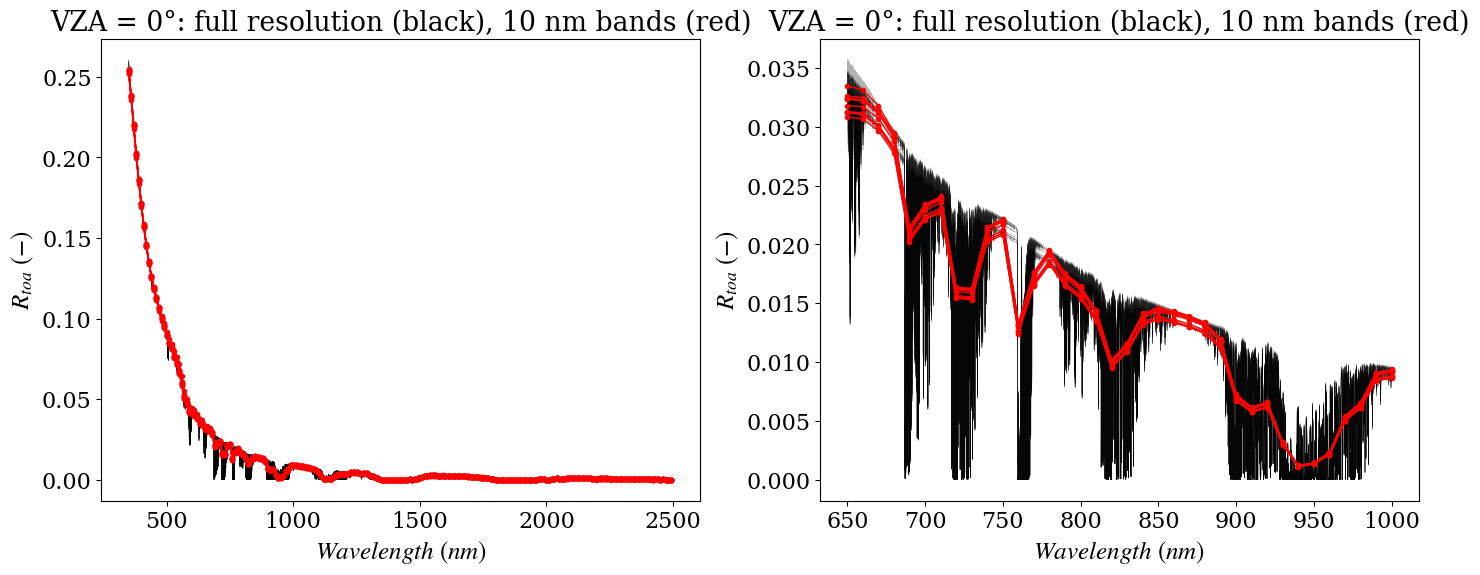

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6))
for ax, wl_range in zip(axs, [slice(350, 2500), slice(650, 1000)]):
    radcalnet_db.Rtoa.sel(vza=0, wl=wl_range).plot(ax=ax, hue='time', color='k', alpha=0.3, lw=0.4,
                                                    add_legend=False)
    radcalnet_10nm.Rtoa.sel(vza=0, wl=wl_range).plot(ax=ax, hue='time', color='r', lw=1, marker='.',
                                                      add_legend=False)
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$R_{toa}\ (-)$')
    ax.set_title('VZA = 0°: full resolution (black), 10 nm bands (red)')
plt.show()

The result is written to NetCDF with `radcalnet_10nm.to_netcdf('AAOT_radcalnet_oc_20250702.nc')`.
The command line `radcalnet_oc` does the simulation and the convolution in one step, with the aerosol
mixture given as argument (see {doc}`../usage`).

## Propagation of the uncertainty

The main sources of uncertainty of the simulation are the remote-sensing reflectance measured at the
surface and the aerosol optical thickness. Their effect on the TOA reflectance is assessed by running
the simulation again with perturbed inputs: $R_{rs}$ multiplied by 0.95 and 1.05 (5 % relative
uncertainty) and $\tau_a(550)$ changed by $\pm 0.01$ (absolute uncertainty of the AERONET AOT), with the
same aerosol mixture, at nadir.

In [10]:
delta_rrs = [0.95, 1., 1.05]
delta_aot = [-0.01, 0., 0.01]
nadir = xr.DataArray([0.], coords={'vza': [0.]}, dims='vza')

rtoa = []
for daot in delta_aot:
    rtoa_ = []
    for drrs in delta_rrs:
        perturbed = input_db.copy()
        perturbed['Rrs'] = input_db.Rrs * drrs
        perturbed['aot550'] = input_db.aot550 + daot
        run = radoc.Process(perturbed, vza=nadir, azi=[90.])
        run.execute(aerosol_combination=aerosol_combination)
        rtoa_.append(spectral.convolve2(run.radcalnet_db.Rtoa, expon=3).Rtoa)
    rtoa.append(xr.concat(rtoa_, dim=xr.DataArray(delta_rrs, dims='delta_rrs', name='delta_rrs')))
rtoa = xr.concat(rtoa, dim=xr.DataArray(delta_aot, dims='delta_aot', name='delta_aot'))

reference = rtoa.sel(delta_rrs=1, delta_aot=0)
# half range of the TOA reflectance for each source, relative to the reference simulation (%)
u_rrs = 100 * (rtoa.sel(delta_aot=0).max('delta_rrs') - rtoa.sel(delta_aot=0).min('delta_rrs')) / 2 / reference
u_aot = 100 * (rtoa.sel(delta_rrs=1).max('delta_aot') - rtoa.sel(delta_rrs=1).min('delta_aot')) / 2 / reference
u_total = np.sqrt(u_rrs ** 2 + u_aot ** 2)

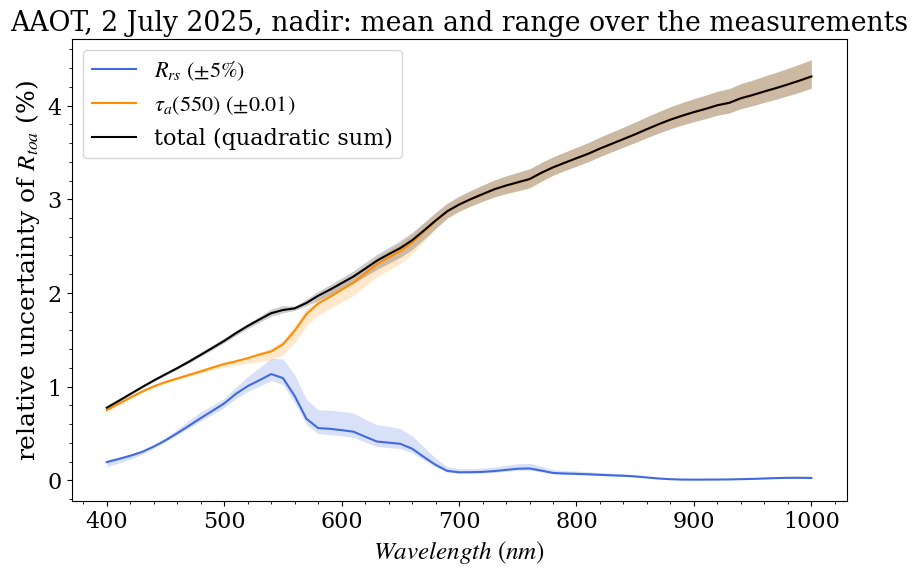

In [11]:
wl_range = slice(400, 1000)
fig, ax = plt.subplots(figsize=(10, 6))
for u, color, label in [(u_rrs, 'royalblue', r'$R_{rs}\ (\pm 5\%)$'),
                        (u_aot, 'darkorange', r'$\tau_a(550)\ (\pm 0.01)$'),
                        (u_total, 'k', 'total (quadratic sum)')]:
    u = u.sel(wl=wl_range).squeeze()
    ax.fill_between(u.wl, u.min('time'), u.max('time'), color=color, alpha=0.2, lw=0)
    ax.plot(u.wl, u.mean('time'), color=color, label=label)
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel(r'relative uncertainty of $R_{toa}$ (%)')
ax.set_title('AAOT, 2 July 2025, nadir: mean and range over the measurements')
ax.legend()
ax.minorticks_on()
plt.show()

In [12]:
# relative uncertainty (%) at a few wavelengths, mean over the measurements
uncertainty = xr.Dataset({'Rrs': u_rrs, 'AOT': u_aot, 'total': u_total}).squeeze(drop=True)
uncertainty.mean('time').sel(wl=[440, 490, 560, 670, 870]).reset_coords(drop=True).to_pandas().round(2)

,Rrs,AOT,total
wl,,,
440,0.36,1.00,1.07
490,0.74,1.20,1.41
560,0.90,1.60,1.84
670,0.25,2.65,2.67
870,0.02,3.80,3.80


The aerosol optical thickness dominates: an error of 0.01 on $\tau_a(550)$ changes the TOA
reflectance by about 1 % in the blue to 4 % at 1000 nm, where the aerosol signal is a larger part of a
smaller total. The 5 % uncertainty of $R_{rs}$ contributes at most about 1 %, in the green where the
water-leaving signal is the largest, and nothing beyond 700 nm. The values above only
cover these two sources, for a clear day and a moderately turbid coastal site: they illustrate the
method rather than give a full uncertainty budget, which also includes the hyperspectral
reconstruction of $R_{rs}$, the aerosol model and the radiative transfer modelling.